In [1]:
import matplotlib.pyplot as plt
import numpy as np 
from scipy.optimize import curve_fit
from tabulate import tabulate

In [2]:
def f_(x): 

    I = integrate.quad(lambda t: t**2 / (np.exp(t) - 1), 0, x)[0]

    return  x**2 / I


In [3]:
# functions to plot on final plot 
# https://docs.scipy.org/doc/scipy-1.18.0/tutorial/integrate.html

# f(1.1) = 2.928
# f(7.5) = 23.799 (23.80)

import scipy.integrate as integrate 


# Debye Temp 
Td_C = 340    # Copper
Td_S = 1000   # Sapphire    

# Thermal conductivity to normalize (looking up values)
k_sapph = 82 # (for T = 200)
k_copp = 463.739  # (for T = 295)


def sapp_theor(T):

    # needing to normalize 
    N = k_sapph / np.exp(Td_S/ (2 * 200))

    return N * np.exp( Td_S / (2 * T))


def f_(x): 
    I = integrate.quad(lambda t: t**2 / (np.exp(t) - 1), 0, x)[0]
    return  x**2 / I

def f(T): 
    W = k_copp / f_(Td_C/295)

    return W * f_(Td_C/ T)



In [4]:

def lin(x, m, c): 
    return m * x + c 

In [5]:
def S_interp(temperatures):
    S_out = []
    T_table = [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 12, 14, 16, 18, 20,
     22, 24, 26, 28, 30, 32, 34, 36, 38, 40, 45, 50, 55, 60, 65,
     70, 75, 80, 85, 90, 100, 120, 140, 160, 180, 200, 250, 273.15, 295]
    S_table = [np.nan, np.nan, 0.99, 1.35, 1.69, 2.01, 2.30, 2.59, 2.86, 3.12, 3.63, 4.12, 4.61, 5.09, 5.58,
     6.06, 6.55, 7.03, 7.52, 7.99, 8.46, 8.92, 9.37, 9.81, 10.23, 11.24, 12.17, 13.03, 13.82, 14.58,
     15.30, 16.01, 16.70, 17.38, 18.05, 19.37, 21.93, 24.42, 26.85, 29.18, 31.42, 36.58, 38.72, 40.42]
    for T in temperatures:
        if T < T_table[0] or T > T_table[-1]:
            S_out.append(float("nan"))
            continue
        for i in range(len(T_table) - 1):
            if T_table[i] <= T <= T_table[i + 1]:
                T0, T1 = T_table[i], T_table[i + 1]
                S0, S1 = S_table[i], S_table[i + 1]
                S_out.append(S0 + (S1 - S0) * (T - T0) / (T1 - T0))
                break
    return S_out[0] *1e-6

In [6]:
# Thermocouples ∆V = SAB(T)∆T
Temp = np.array([3,4,5,6,7,8,9,10,12,14,16,18,20,22,24,26,28,30,32,34,36,38,40,45,50,55,60,65,70,75,85,90,100,120,140,160,180,200,250,273.15,295])
S_AB = np.array([0.99,1.35,1.69,2.01,2.30,2.59,2.86,3.12,3.63,4.12, 4.61, 5.09, 5.58, 6.06, 6.55, 7.03, 7.52, 7.99, 8.46, 8.92, 9.37, 9.81, 10.23, 11.24, 12.17, 13.03, 13.82, 14.58, 15.30, 16.01, 16.70, 17.38, 18.05, 19.37, 21.93, 24.42, 26.85, 29.18, 31.42, 38.72, 40.42])

def S(t): 
    i = np.where(Temp == t)[0][0]
    return S_AB[i]

# finding dT from dV:

def dT(dV, S):
    return dV / S
    
# errors via quadrature, with S_err: 
def dT_err_S(dV, S, dV_err, S_err):  
    return np.sqrt( ( dV_err / S) ** 2 + ((dV * S_err )/ (S ** 2) ) ** 2 )

# errors via quadrature (just error in dV)
def dt_err(S, dV_err):
    return dV_err / S


In [7]:
# calculating cross sectional area (mm2)

# copper: 
r_C = 1.90 / 2 * 1e-3
r_C_err = 0.025  * 1e-3

A_C = np.pi * (r_C ** 2) 
A_C_err = 2 * np.pi * r_C * r_C_err  #error in quadrature 

# sapphire 
r_S = (3 / 2 ) * 1e-3
r_S_err = 0.025 * 1e-3

A_S = np.pi * (r_S ** 2)
A_S_err = 2 * np.pi * r_S * r_S_err #error in quadrature 

# distance (mm) between thermocouple junctions (cross section A above)
dx_C = 29.50 * 1e-3
dx_C_err = 0.05 * 1e-3

dx_S = 30.20 * 1e-3
dx_S_err = 0.05 * 1e-3

T_values = []
S_b_values = []

P_C_values = []
P_S_values = []

dT_C_values = []
dT_C_err_values = []

dT_S_values = []
dT_S_err_values = []

In [8]:
# measurement 1 : Room Temperature 
 
# set point temperature 
T_1 = 295.0
T_values.append(T_1)

# seedbeck coefficient
S_b_1 =  S_interp([T_1]) 
S_b_values.append(S_b_1)

# power: -----------------------
voltage_copper_1  = np.array([0, 0.47, 0.65, 1.09, 1.54, 2.16 ])  # V
voltage_sapphire_1 = np.array([0, 0.62, 0.83, 1.32, 2.00]) #, 1.905 

current_copper_1 = np.array([0, 0.010, 0.014, 0.024, 0.035, 0.043 ])
current_sapphire_1 = np.array([0, 0.010, 0.015, 0.024, 0.035 ]) # 0.043

P_C_values.append( voltage_copper_1 * current_copper_1 )  # error in power should result from resolution of equipment 
P_S_values.append(voltage_sapphire_1 * current_sapphire_1) # and be smaller than error from T

# voltages + error -------------

# copper 
dV_C_1 = np.array([0, 4.9000e-06, 9.5200e-06, 2.6113e-05, 5.1408e-05, 7.6891e-05])
dV_C_err_1 = np.array([0, 9.8973e-08, 6.3574e-08, 1.3008e-07, 3.1376e-07, 3.9295e-07 ]) + 5.7074e-08

# sapphire 
dV_S_1 = np.array([0, 2.5278e-05, 4.5418e-05, 1.1291e-04, 2.3264e-04]) #, 3.4305e-04
dV_S_err_1 = np.array([0, 2.0133e-07, 1.7213e-07, 1.9489e-07, 2.0376e-07]) + 6.0724e-08 #, 2.6316e-07

# converting dV to dT (assuming no error on S - will change if necessary)
dT_C_values.append(dV_C_1 / S_b_1)
dT_C_err_values.append(dV_C_err_1 / S_b_1)

dT_S_values.append(dV_S_1 / S_b_1)
dT_S_err_values.append(dV_S_err_1 / S_b_1)



In [9]:
# measurement 2: 15K
 
# set point temperature 
T_2 = 15
T_values.append(T_2)

# seedbeck coefficient
S_b_2 =  S_interp([T_2])   #S(T_ref)
S_b_values.append(S_b_2)

# power: -----------------------
 
voltage_copper_2  = np.array([0, 0.86, 1.25, 1.67 ])
voltage_sapphire_2 = np.array([0, 1.02, 1.47, 1.94 ])

current_copper_2 = np.array([0, 0.02, 0.030, 0.040  ])
current_sapphire_2 = np.array([0, 0.02, 0.030, 0.040  ])

P_C_values.append(voltage_copper_2 * current_copper_2)   # error in power should result from resolution of equipment and be smaller than error from T
P_S_values.append( voltage_sapphire_2 * current_sapphire_2 )
# voltages + error -------------

# copper 
dV_C_2 = np.array([0, 4.4886e-07, 8.9515e-07, 1.3620e-06 ])
dV_C_err_2 = np.array([0, 2.2003e-07, 2.1749e-07, 2.1671e-07]) + 2.1824e-07

# sapphire 
dV_S_2 = np.array([0, 3.6472e-07, 7.7124e-07, 1.2836e-06])
dV_S_err_2 = np.array([0, 1.1801e-07, 1.1801e-07, 1.3208e-07]) + 1.2250e-07

# converting dV to dT (assuming no error on S - will change if necessary)
dT_C_values.append(dV_C_2 / S_b_2)
dT_C_err_values.append(dV_C_err_2 / S_b_2)

dT_S_values.append(dV_S_2 / S_b_2)
dT_S_err_values.append(dV_S_err_2 / S_b_2)

In [10]:
# measurement 3: 20K
 
# set point temperature 
T_3 = 20
T_values.append(T_3)

# seedbeck coefficient
S_b_3 =  S_interp([T_3])   #S(T_ref)
S_b_values.append(S_b_3)

# power: -----------------------
 
voltage_copper_3  = np.array([0, 0.88, 1.29 , 1.69])
voltage_sapphire_3 = np.array([0, 1.06, 1.47 ,1.97 ])

current_copper_3 = np.array([0, 0.021, 0.030, 0.040 ])
current_sapphire_3 = np.array([0, 0.021, 0.030, 0.040 ])

P_C_values.append(voltage_copper_3 * current_copper_3)   # error in power should result from resolution of equipment and be smaller than error from T
P_S_values.append(voltage_sapphire_3 * current_sapphire_3)
# voltages + error -------------

# copper 
dV_C_3 = np.array([0,5.637854451775797e-07,1.0241087277216577e-06,1.5338450687071696e-06 ])
dV_C_err_3 = np.array([0,2.3640705596015358e-07,2.3908329771495287e-07,2.407625004967776e-07]) + 2.451820185102013e-07

# sapphire 
dV_S_3 = np.array([0,3.704986482441791e-07,7.914835579429134e-07,1.2772815148866888e-06])
dV_S_err_3 = np.array([0,3.092664690837591e-07,3.082151041549983e-07,3.0038186157942096e-07]) + 3.13757438504381e-07

# converting dV to dT (assuming no error on S - will change if necessary)
dT_C_values.append(dV_C_3 / S_b_3)
dT_C_err_values.append( dV_C_err_3 / S_b_3)

dT_S_values.append( dV_S_3 / S_b_3)
dT_S_err_values.append(dV_S_err_3 / S_b_3)

In [11]:
# measurement 4: 30K
T_4 = 30 
T_values.append(T_4)

# seedbeck coefficient
S_b_4 =  S_interp([T_4])   #S(T_ref)
S_b_values.append(S_b_4)

# power: -----------------------
 
voltage_copper_4  = np.array([0, 0.87, 1.30, 1.70 ])

voltage_sapphire_4 = np.array([0, 1.03, 1.48, 1.96  ])

current_copper_4 = np.array([0, 0.020, 0.030, 0.040 ])
current_sapphire_4 = np.array([0, 0.020, 0.030, 0.040 ])

P_C_values.append(voltage_copper_4 * current_copper_4)   # error in power should result from resolution of equipment and be smaller than error from T
P_S_values.append(voltage_sapphire_4 * current_sapphire_4)
# voltages + error -------------

# copper 
dV_C_4 = np.array([0,1.0600425604821712e-06,2.00627862236739e-06,3.2898570194349824e-06])
dV_C_err_4 = np.array([1.0655762146807841e-07,1.0655762146807841e-07,1.1286053800711342e-07,8.775709878181666e-08 ]) + 1.0655762146807841e-07

# sapphire 
dV_S_4 = np.array([0,5.77333259010098e-07,9.6903015769457e-07,1.6549314831384748e-06 ])
dV_S_err_4 = np.array([0,1.1913996194143759e-07,1.195118317664494e-07,1.1344220765361831e-07 ]) + 1.1913996194143759e-07

# converting dV to dT (assuming no error on S - will change if necessary)
dT_C_values.append(dV_C_4 / S_b_4)
dT_C_err_values.append(dV_C_err_4 / S_b_4)

dT_S_values.append(dV_S_4 / S_b_4)
dT_S_err_values.append( dV_S_err_4 / S_b_4)

In [12]:
# measurement 5: 40K
T_5 = 40 
T_values.append(T_5)

# seedbeck coefficient
S_b_5 =  S_interp([T_5])   #S(T_ref)
S_b_values.append(S_b_5)

# power: -----------------------
 
voltage_copper_5  = np.array([0, 0.85, 1.29, 1.71])

voltage_sapphire_5 = np.array([0, 1.04, 1.51, 1.97])

current_copper_5 = np.array([0, 0.020, 0.030, 0.040 ])
current_sapphire_5 = np.array([0, 0.020, 0.030, 0.040 ])

P_C_values.append(voltage_copper_5 * current_copper_5)   # error in power should result from resolution of equipment and be smaller than error from T
P_S_values.append(voltage_sapphire_5 * current_sapphire_5)
# voltages + error -------------

# copper 
dV_C_5 = np.array([0,1.265062152427356e-06,2.8410921385122955e-06,5.187568830187814e-06   ])
dV_C_err_5 = np.array([0,9.322151213697913e-08,9.686598803106015e-08,1.087917050747741e-07 ]) + 8.650746552330928e-08

# sapphire 
dV_S_5 = np.array([0,4.239737477740865e-07,9.667176941079482e-07,1.606471782222201e-06 ])
dV_S_err_5 = np.array([0,7.379000531973439e-08,9.251295425236258e-08,7.676141588179177e-08 ]) + 8.039971120593082e-08

# converting dV to dT (assuming no error on S - will change if necessary)
dT_C_values.append(dV_C_5 / S_b_5)
dT_C_err_values.append(dV_C_err_5 / S_b_5)

dT_S_values.append(dV_S_5 / S_b_5)
dT_S_err_values.append(dV_S_err_5 / S_b_5)

In [13]:
# measurement 6: 50K
T_6 = 50 
T_values.append(T_6)

# seedbeck coefficient
S_b_6 =  S_interp([T_6])   #S(T_ref)
S_b_values.append(S_b_6)

# power: -----------------------
 
voltage_copper_6  = np.array([0, 0.87, 1.31, 1.71 ])

voltage_sapphire_6 = np.array([0, 1.05, 1.50, 1.99])

current_copper_6 = np.array([0, 0.020, 0.030, 0.040 ])
current_sapphire_6 = np.array([0, 0.020, 0.030, 0.040 ])

P_C_values.append(voltage_copper_6 * current_copper_6)  # error in power should result from resolution of equipment and be smaller than error from T
P_S_values.append(voltage_sapphire_6 * current_sapphire_6) 
# voltages + error -------------

# copper 
dV_C_6 = np.array([0,2.321886901609156e-06,5.246242725599814e-06,9.160680386935391e-06   ])
dV_C_err_6 = np.array([0,8.650746552330928e-08,9.322151213697913e-08,9.686598803106015e-08]) + 8.650746552330928e-08

# sapphire 
dV_S_6 = np.array([0,4.688070026801076e-07,1.0578074818535146e-06,1.76516727181018e-06])
dV_S_err_6 = np.array([0,8.039971120593082e-08,7.379000531973439e-08,9.251295425236258e-08]) + 8.039971120593082e-08

# converting dV to dT (assuming no error on S - will change if necessary)
dT_C_values.append(dV_C_6 / S_b_6)
dT_C_err_values.append(dV_C_err_6 / S_b_6)

dT_S_values.append(dV_S_6 / S_b_6)
dT_S_err_values.append(dV_S_err_6 / S_b_6)

In [14]:
# measurement 7: 25K 
T_7 =  25
T_values.append(T_7)

# seedbeck coefficient
S_b_7 =  S_interp([T_7])   #S(T_ref)
S_b_values.append(S_b_7)

# power: -----------------------
 
voltage_copper_7  = np.array([0, 0.87, 1.31, 1.72])

voltage_sapphire_7 = np.array([0, 1.05, 1.50, 2.00])

current_copper_7 = np.array([0, 0.020, 0.030, 0.040])
current_sapphire_7 = np.array([0, 0.020, 0.030, 0.040])

P_C_values.append(voltage_copper_6 * current_copper_6)  # error in power should result from resolution of equipment and be smaller than error from T
P_S_values.append(voltage_sapphire_6 * current_sapphire_6) 
# voltages + error -------------

# copper 
dV_C_7 = np.array([0,6.753907239539173e-07,1.6388750682003498e-06,2.490172191451173e-06 ])
dV_C_err_7 = np.array([0,1.2271733595043388e-07,1.1362887670474611e-07,9.094800512614874e-08]) + 1.2232413823107136e-07

# sapphire 
dV_S_7 = np.array([0,4.45046953045122e-07,8.960118068279675e-07,1.4445978654645475e-06])
dV_S_err_7 = np.array([0,1.8136795735690336e-07,1.7499528707800892e-07,1.7074103056780301e-07]) + 1.8401694852848212e-07

# converting dV to dT (assuming no error on S - will change if necessary)
dT_C_values.append(dV_C_7 / S_b_7)
dT_C_err_values.append(dV_C_err_7 / S_b_7)

dT_S_values.append(dV_S_7 / S_b_7)
dT_S_err_values.append(dV_S_err_7 / S_b_7)


In [15]:
# measurement 8: 60K
T_8 = 60 
T_values.append(T_8)

# seedbeck coefficient
S_b_8 =  S_interp([T_8])   #S(T_ref)
S_b_values.append(S_b_8)

# power: -----------------------
 
voltage_copper_8  = np.array([0, 0.88, 1.31, 1.72])

voltage_sapphire_8 = np.array([0, 1.05, 1.55, 2.02])

current_copper_8 = np.array([0, 0.020, 0.030, 0.040])
current_sapphire_8 = np.array([0, 0.020, 0.030, 0.040])

P_C_values.append(voltage_copper_8 * current_copper_8)  # error in power should result from resolution of equipment and be smaller than error from T
P_S_values.append(voltage_sapphire_8 * current_sapphire_8) 
# voltages + error -------------

# copper 
dV_C_8 = np.array([0,3.666591869745315e-06,8.195555264263216e-06,1.4330481970922648e-05])
dV_C_err_8 = np.array([0,8.229861948011774e-08,1.1941103031554975e-07,1.4794671322091854e-07]) + 8.229861948011774e-08

# sapphire 
dV_S_8 = np.array([0,8.762655570779035e-07,1.8871932835790336e-06,3.244426124886577e-06])
dV_S_err_8 = np.array([0,7.375514146495752e-08,6.530066137726895e-08,7.057716475333221e-08]) + 7.375514146495752e-08

# converting dV to dT (assuming no error on S - will change if necessary)
dT_C_values.append(dV_C_8 / S_b_8)
dT_C_err_values.append(dV_C_err_8 / S_b_8)

dT_S_values.append(dV_S_8 / S_b_8)
dT_S_err_values.append(dV_S_err_8 / S_b_8)

In [ ]:

# measurement 9: 80K
T_9 = 80 
T_values.append(T_9)

# seedbeck coefficient
S_b_9 =  S_interp([T_9])   #S(T_ref)
S_b_values.append(S_b_9)

# power: -----------------------
 
voltage_copper_9  = np.array([0, 0.46, 0.89, 1.30, 1.74])

voltage_sapphire_9 = np.array([0, 0.58, 1.05, 1.55, 2.02])

current_copper_9 = np.array([0, 0.010, 0.020, 0.030, 0.040 ])
current_sapphire_9 = np.array([0, 0.010, 0.020, 0.030, 0.040 ])

P_C_values.append(voltage_copper_9 * current_copper_9)  # error in power should result from resolution of equipment and be smaller than error from T
P_S_values.append(voltage_sapphire_9 * current_sapphire_8) 
# voltages + error -------------

# copper 
dV_C_9 = np.array([ ])
dV_C_err_9 = np.array([]) + 8.650746552330928e-08

# sapphire 
dV_S_9 = np.array([ ])
dV_S_err_9 = np.array([ ]) + 8.039971120593082e-08

# converting dV to dT (assuming no error on S - will change if necessary)
dT_C_values.append(dV_C_9 / S_b_9)
dT_C_err_values.append(dV_C_err_9 / S_b_9)

dT_S_values.append(dV_S_9 / S_b_9)
dT_S_err_values.append(dV_S_err_9 / S_b_9)
'''

' \n# measurement 9: 80K\nT_9 = 80 \nT_values.append(T_9)\n\n# seedbeck coefficient\nS_b_9 =  S_interp([T_9])   #S(T_ref)\nS_b_values.append(S_b_9)\n\n# power: -----------------------\n\nvoltage_copper_9  = np.array([0, 0.87, 1.31, 1.71 ])\n\nvoltage_sapphire_9 = np.array([0, 1.05, 1.50, 1.99])\n\ncurrent_copper_9 = np.array([0, 0.020, 0.030, 0.040 ])\ncurrent_sapphire_9 = np.array([0, 0.020, 0.030, 0.040 ])\n\nP_C_values.append(voltage_copper_9 * current_copper_9)  #\xa0error in power should result from resolution of equipment and be smaller than error from T\nP_S_values.append(voltage_sapphire_9 * current_sapphire_8) \n# voltages + error -------------\n\n# copper \ndV_C_9 = np.array([ ])\ndV_C_err_9 = np.array([0,8.650746552330928e-08,9.322151213697913e-08,9.686598803106015e-08]) + 8.650746552330928e-08\n\n# sapphire \ndV_S_9 = np.array([0,4.688070026801076e-07,1.0578074818535146e-06,1.76516727181018e-06])\ndV_S_err_9 = np.array([0,8.039971120593082e-08,7.379000531973439e-08,9.251295

In [17]:
''' 
# measurement 10: 100K
T_10 = 80 
T_values.append(T_9)

# seedbeck coefficient
S_b_9 =  S_interp([T_9])   #S(T_ref)
S_b_values.append(S_b_9)

# power: -----------------------
 
voltage_copper_10  = np.array([0, 0.87, 1.31, 1.71 ])

voltage_sapphire_10 = np.array([0, 1.05, 1.50, 1.99])

current_copper_10 = np.array([0, 0.020, 0.030, 0.040 ])
current_sapphire_10 = np.array([0, 0.020, 0.030, 0.040 ])

P_C_values.append(voltage_copper_10 * current_copper_10)  # error in power should result from resolution of equipment and be smaller than error from T
P_S_values.append(voltage_sapphire_10 * current_sapphire_10) 
# voltages + error -------------

# copper 
dV_C_10 = np.array([ ])
dV_C_err_10 = np.array([0,8.650746552330928e-08,9.322151213697913e-08,9.686598803106015e-08]) + 8.650746552330928e-08

# sapphire 
dV_S_10 = np.array([0,4.688070026801076e-07,1.0578074818535146e-06,1.76516727181018e-06])
dV_S_err_10 = np.array([0,8.039971120593082e-08,7.379000531973439e-08,9.251295425236258e-08]) + 8.039971120593082e-08

# converting dV to dT (assuming no error on S - will change if necessary)
dT_C_values.append(dV_C_10 / S_b_10)
dT_C_err_values.append(dV_C_err_10 / S_b_10)

dT_S_values.append(dV_S_10 / S_b_10)
dT_S_err_values.append(dV_S_err_10 / S_b_10)
'''

' \n# measurement 10: 100K\nT_10 = 80 \nT_values.append(T_9)\n\n# seedbeck coefficient\nS_b_9 =  S_interp([T_9])   #S(T_ref)\nS_b_values.append(S_b_9)\n\n# power: -----------------------\n\nvoltage_copper_10  = np.array([0, 0.87, 1.31, 1.71 ])\n\nvoltage_sapphire_10 = np.array([0, 1.05, 1.50, 1.99])\n\ncurrent_copper_10 = np.array([0, 0.020, 0.030, 0.040 ])\ncurrent_sapphire_10 = np.array([0, 0.020, 0.030, 0.040 ])\n\nP_C_values.append(voltage_copper_10 * current_copper_10)  #\xa0error in power should result from resolution of equipment and be smaller than error from T\nP_S_values.append(voltage_sapphire_10 * current_sapphire_10) \n# voltages + error -------------\n\n# copper \ndV_C_10 = np.array([ ])\ndV_C_err_10 = np.array([0,8.650746552330928e-08,9.322151213697913e-08,9.686598803106015e-08]) + 8.650746552330928e-08\n\n# sapphire \ndV_S_10 = np.array([0,4.688070026801076e-07,1.0578074818535146e-06,1.76516727181018e-06])\ndV_S_err_10 = np.array([0,8.039971120593082e-08,7.3790005319734

In [18]:
''' 
# measurement 11: 120K
T_11 = 120 
T_values.append(T_11)

# seedbeck coefficient
S_b_11 =  S_interp([T_11])   #S(T_ref)
S_b_values.append(S_b_11)

# power: -----------------------
 
voltage_copper_11  = np.array([0, 0.87, 1.31, 1.71 ])

voltage_sapphire_11 = np.array([0, 1.05, 1.50, 1.99])

current_copper_11 = np.array([0, 0.020, 0.030, 0.040 ])
current_sapphire_11 = np.array([0, 0.020, 0.030, 0.040 ])

P_C_values.append(voltage_copper_11 * current_copper_11)  # error in power should result from resolution of equipment and be smaller than error from T
P_S_values.append(voltage_sapphire_11 * current_sapphire_11) 
# voltages + error -------------

# copper 
dV_C_11 = np.array([ ])
dV_C_err_11 = np.array([0,8.650746552330928e-08,9.322151213697913e-08,9.686598803106015e-08]) + 8.650746552330928e-08

# sapphire 
dV_S_11 = np.array([0,4.688070026801076e-07,1.0578074818535146e-06,1.76516727181018e-06])
dV_S_err_11 = np.array([0,8.039971120593082e-08,7.379000531973439e-08,9.251295425236258e-08]) + 8.039971120593082e-08

# converting dV to dT (assuming no error on S - will change if necessary)
dT_C_values.append(dV_C_11 / S_b_11)
dT_C_err_values.append(dV_C_err_11 / S_b_11)

dT_S_values.append(dV_S_11 / S_b_11)
dT_S_err_values.append(dV_S_err_11 / S_b_11)
'''

' \n# measurement 11: 120K\nT_11 = 120 \nT_values.append(T_11)\n\n# seedbeck coefficient\nS_b_11 =  S_interp([T_11])   #S(T_ref)\nS_b_values.append(S_b_11)\n\n# power: -----------------------\n\nvoltage_copper_11  = np.array([0, 0.87, 1.31, 1.71 ])\n\nvoltage_sapphire_11 = np.array([0, 1.05, 1.50, 1.99])\n\ncurrent_copper_11 = np.array([0, 0.020, 0.030, 0.040 ])\ncurrent_sapphire_11 = np.array([0, 0.020, 0.030, 0.040 ])\n\nP_C_values.append(voltage_copper_11 * current_copper_11)  #\xa0error in power should result from resolution of equipment and be smaller than error from T\nP_S_values.append(voltage_sapphire_11 * current_sapphire_11) \n# voltages + error -------------\n\n# copper \ndV_C_11 = np.array([ ])\ndV_C_err_11 = np.array([0,8.650746552330928e-08,9.322151213697913e-08,9.686598803106015e-08]) + 8.650746552330928e-08\n\n# sapphire \ndV_S_11 = np.array([0,4.688070026801076e-07,1.0578074818535146e-06,1.76516727181018e-06])\ndV_S_err_11 = np.array([0,8.039971120593082e-08,7.37900053

In [19]:
''' 
# measurement 12: 180K
T_12 = 180 
T_values.append(T_12)

# seedbeck coefficient
S_b_12 =  S_interp([T_12])   #S(T_ref)
S_b_values.append(S_b_12)

# power: -----------------------
 
voltage_copper_12  = np.array([0, 0.87, 1.31, 1.71 ])

voltage_sapphire_12 = np.array([0, 1.05, 1.50, 1.99])

current_copper_12 = np.array([0, 0.020, 0.030, 0.040 ])
current_sapphire_12 = np.array([0, 0.020, 0.030, 0.040 ])

P_C_values.append(voltage_copper_12 * current_copper_12)  # error in power should result from resolution of equipment and be smaller than error from T
P_S_values.append(voltage_sapphire_12 * current_sapphire_12) 
# voltages + error -------------

# copper 
dV_C_12 = np.array([ ])
dV_C_err_12 = np.array([0,8.650746552330928e-08,9.322151213697913e-08,9.686598803106015e-08]) + 8.650746552330928e-08

# sapphire 
dV_S_12 = np.array([0,4.688070026801076e-07,1.0578074818535146e-06,1.76516727181018e-06])
dV_S_err_12 = np.array([0,8.039971120593082e-08,7.379000531973439e-08,9.251295425236258e-08]) + 8.039971120593082e-08

# converting dV to dT (assuming no error on S - will change if necessary)
dT_C_values.append(dV_C_12 / S_b_12)
dT_C_err_values.append(dV_C_err_12 / S_b_12)

dT_S_values.append(dV_S_12 / S_b_12)
dT_S_err_values.append(dV_S_err_12 / S_b_12)
'''

' \n# measurement 12: 180K\nT_12 = 180 \nT_values.append(T_12)\n\n# seedbeck coefficient\nS_b_12 =  S_interp([T_12])   #S(T_ref)\nS_b_values.append(S_b_12)\n\n# power: -----------------------\n\nvoltage_copper_12  = np.array([0, 0.87, 1.31, 1.71 ])\n\nvoltage_sapphire_12 = np.array([0, 1.05, 1.50, 1.99])\n\ncurrent_copper_12 = np.array([0, 0.020, 0.030, 0.040 ])\ncurrent_sapphire_12 = np.array([0, 0.020, 0.030, 0.040 ])\n\nP_C_values.append(voltage_copper_12 * current_copper_12)  #\xa0error in power should result from resolution of equipment and be smaller than error from T\nP_S_values.append(voltage_sapphire_12 * current_sapphire_12) \n# voltages + error -------------\n\n# copper \ndV_C_12 = np.array([ ])\ndV_C_err_12 = np.array([0,8.650746552330928e-08,9.322151213697913e-08,9.686598803106015e-08]) + 8.650746552330928e-08\n\n# sapphire \ndV_S_12 = np.array([0,4.688070026801076e-07,1.0578074818535146e-06,1.76516727181018e-06])\ndV_S_err_12 = np.array([0,8.039971120593082e-08,7.37900053

In [20]:
# finding K (thermal conductivity from gradient) P = ( k A / dx ) * (dT)
# to include errors in dT, fitting dT = (dx /(kA)) * P

 # dx_C and A_C (and S) same for every measurement 

def k_and_plot(T, P_C, P_S, dT_C, dT_S, dT_C_err, dT_S_err, y): 

    p, pcov = curve_fit(lin, P_C, dT_C, sigma = dT_C_err, absolute_sigma= True)
    a_C, b_C = p
    a_C_err = np.sqrt(np.diag(pcov))[0]

    K_C = (dx_C) / ( (A_C) * a_C)

    K_C_error = np.sqrt( ( dx_C_err / (A_C * a_C) ) ** 2 + ((dx_C * a_C_err ) / (A_C * a_C**2)) **2 + ( (dx_C * A_C_err)/ (a_C * A_C**2))**2) 



    p, pcov = curve_fit(lin, P_S, dT_S, sigma = dT_S_err, absolute_sigma= True)
    a_S, b_S = p
    a_S_err = np.sqrt(np.diag(pcov))[0]

    K_S = (dx_S ) / ( (A_S) * a_S)
    K_S_error = np.sqrt( ( dx_S_err / (A_S * a_S) ) ** 2 + ((dx_S * a_S_err ) / (A_S * a_S**2)) **2 + ( (dx_S * A_S_err)/ (a_S * A_S**2))**2) 

    if y == True: 
        plt.errorbar(P_C, dT_C, yerr = dT_C_err, fmt = 'o', color = 'red', label = 'copper')
        plt.plot(P_C, lin(P_C, a_C, b_C), label = 'copper fitted')

        plt.errorbar(P_S, dT_S, yerr = dT_S_err, fmt = 'o', color = 'blue', label = 'sapphire')
        plt.plot(P_S, lin(P_S, a_S, b_S), label = 'sapphire fitted')
        plt.title(f"dT vs power : Temp = {T}K ")
        plt.xlabel('Power (W)')
        plt.ylabel('dT (K)')
        plt.legend()
        plt.show()

        plt.scatter(P_C, dT_C - lin(P_C, a_C, b_C), color = 'red', label = 'residuals copper' )
        plt.scatter(P_S, dT_S - lin(P_S, a_S, b_S), color = 'blue', label = 'residuals sapphire' )
        plt.xlabel('Power residuals (W)')
        plt.ylabel('dT residuals (K)')
        plt.title('Residuals')
        plt.legend()
        plt.show()

    return K_C, K_C_error, K_S, K_S_error



[295.0, 15, 20, 30, 40, 50, 25, 60]


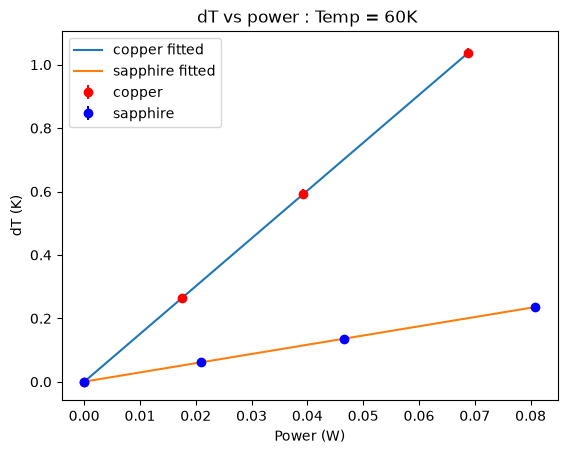

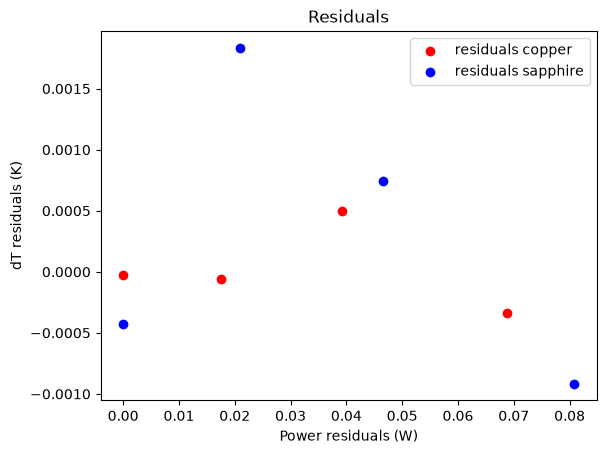

  Temp (K)    k: Copper Wm-1K-1     error    k: Sapphire Wm-1K-1      error
----------  -------------------  --------  ---------------------  ---------
       295              467.345   24.6808                51.2511    1.71133
        15             2159.6    711.395               1113.79    227.441
        20             2477.34   806.619               1443.12    721.617
        30             1752.26   174.161               1607.86    243.586
        40             1413.42    91.8601              2127.22    230.36
        50              946.105   53.4699              2312.87    238.933
        25             1898.09   201.433               1571.19    405.632
        60              690.126   37.7998              1467.42     83.9542


In [21]:
K_copper = []
K_copper_err = []
K_sapphire = []
K_sapphire_err = []

print(T_values)

Y = [60]

for i in range(len(T_values)):
    
    if T_values[i] in Y:
        y = True
    else:
        y = False
        
    values = k_and_plot(T_values[i], P_C_values[i], P_S_values[i], dT_C_values[i], dT_S_values[i], dT_C_err_values[i], dT_S_err_values[i], y )

    K_copper.append(values[0])
    K_copper_err.append(values[1])
    K_sapphire.append(values[2])
    K_sapphire_err.append(values[3])

print(tabulate(zip(T_values, K_copper, K_copper_err, K_sapphire, K_sapphire_err), headers = ['Temp (K)', 'k: Copper Wm-1K-1', 'error', 'k: Sapphire Wm-1K-1', 'error']  ))


Plotting Thermal conductivity vs T


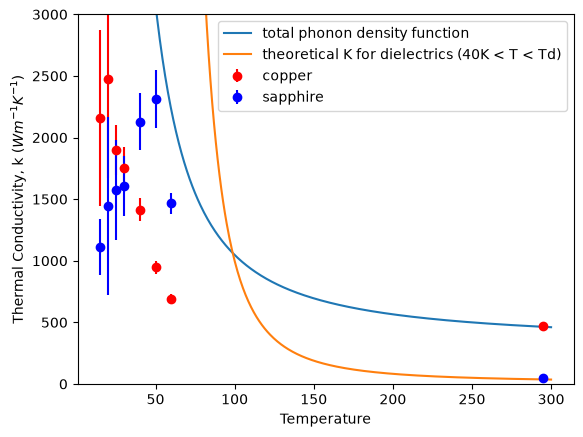

/var/folders/gz/d9nwr3l52nl17x5ytrbxn9m40000gn/T/ipykernel_25411/1688839065.py:27: UserWarning: Attempt to set non-positive ylim on a log-scaled axis will be ignored.
  plt.ylim(0, 5000)


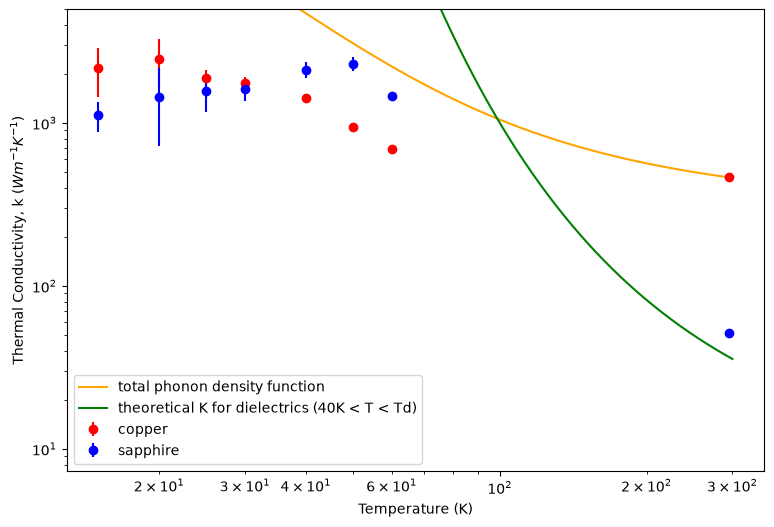

In [22]:
x_values = np.linspace(15, 300, 500, endpoint = True)

plt.errorbar( T_values, K_copper, yerr = K_copper_err, fmt = 'o', color = 'red', label = 'copper')
plt.errorbar( T_values, K_sapphire, yerr = K_sapphire_err, fmt = 'o', color = 'blue', label = 'sapphire')
'''
plt.plot(T_values[1:], K_copper[1:], color = 'red', label = 'copper')
plt.plot(T_values[1:], K_sapphire[1:], color = 'blue', label = 'sapphire')
'''
plt.plot(x_values, [f(x) for x in x_values], label = 'total phonon density function')
plt.plot(x_values, sapp_theor(x_values), label = 'theoretical K for dielectrics (40K < T < Td)')
plt.xlabel("Temperature")
plt.ylabel(r"Thermal Conductivity, k (${Wm^{-1}K^{-1}}$)")
plt.ylim(0, 3000)
plt.legend()
plt.show()


fig, ax = plt.subplots(figsize = (9, 6))
ax.plot(x_values, [f(x) for x in x_values], color = 'orange', label = 'total phonon density function')
ax.plot(x_values, sapp_theor(x_values), color = 'green', label = 'theoretical K for dielectrics (40K < T < Td)')
ax.errorbar(T_values, K_copper, yerr = K_copper_err, fmt = 'o', color = 'red', label = 'copper')
ax.errorbar( T_values, K_sapphire, yerr = K_sapphire_err, fmt = 'o', color = 'blue', label = 'sapphire')


ax.set_xscale("log")
ax.set_yscale("log")
plt.ylim(0, 5000)
plt.xlabel("Temperature (K)")
plt.ylabel(r"Thermal Conductivity, k (${Wm^{-1}K^{-1}}$)")
plt.legend()
plt.show()
